<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [scikit-bio](https://github.com/Query-farm/vgi-scikit-bio)

Bioinformatics functions for sequence analysis, alignment, microbial diversity, ordination and phylogenetic trees.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-scikit-bio/blob/main/notebooks/02_orientation_before_composition.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-scikit-bio/blob/main/notebooks/README.md)


## 02 · Orientation before composition

Can two representations of the same short DNA string appear different in a composition profile? We retain every input during quality control, explicitly remove gaps for one comparison, and contrast oriented k-mers with reverse-complement-collapsed k-mers.

The six inputs are **authored synthetic strings**: forward, reverse-complement, gapped, ambiguous, malformed and missing. No sequencing instrument, organism or quality score is represented. Alphabet validity does not prove biological identity. `KMER_K` is an integer from **2 to 5**, default **3**; the experiment uses **2**.

In [1]:
KMER_K = 3  # overlapping word length in bases; experiment: 2

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.29":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.29"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the kernel, then run all cells.")

from vgi_notebooks import check_runtime  # noqa: E402

check_runtime()

In [3]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import display
from vgi_notebooks import connect
from vgi_notebooks.presentation import finish, prose, theme

if type(KMER_K) is not int or not 2 <= KMER_K <= 5:
    raise ValueError("KMER_K must be an integer from 2 to 5.")
theme()
session = connect(globals())
Path("artifacts").mkdir(exist_ok=True)
SOURCE = "Source: authored synthetic inputs · actual vgi-scikit-bio v0.3.0 worker · no biological inference"

### Connect to the released scientific worker

The short literal Git-tag launcher uses **v0.3.0** in a separate Python 3.13 process. Its release owns scientific and protocol dependencies; no source checkout or transitive overrides are needed. The notebook kernel uses the shared base package. First use downloads the worker and VGI; all analytical inputs below are synthetic and local. Shared connection setup creates an empty temporary SQL secret directory and disables persistent secrets.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'skbio' (TYPE vgi,
 LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-scikit-bio@v0.3.0 vgi-scikit-bio');

,Success


### Preserve missing, invalid and ambiguous states

`is_valid_dna` accepts the DNA alphabet, including its gap/ambiguity symbols. `has_gaps` and `has_degenerates` therefore answer separate questions. A NULL input remains unknown. We apply `degap` explicitly but do not resolve an `N` into an invented base; only valid, unambiguous strings enter the profiles.

In [5]:
%%sql
CREATE TABLE reads AS SELECT * FROM (VALUES
 ('forward','ATGCGGATTACAGGT'),
 ('reverse','ACCTGTAATCCGCAT'),
 ('gapped','ATGC-GGATTA-CAGGT'),
 ('ambiguous','ATGNGGATTACAGGT'),
 ('malformed','NOT_DNA!'),
 ('missing',NULL)
) AS t(read_id,seq);
CREATE TABLE quality AS SELECT read_id,seq,
 skbio.sequence.is_valid_dna(seq) AS valid_dna,
 skbio.sequence.has_gaps(seq) AS has_gaps,
 skbio.sequence.has_degenerates(seq) AS has_degenerates,
 skbio.sequence.degap(seq) AS gapless
FROM reads;
CREATE TABLE eligible AS SELECT read_id,gapless AS seq FROM quality
WHERE valid_dna AND NOT has_degenerates;
SELECT *,CASE WHEN seq IS NULL THEN 'missing'
 WHEN NOT valid_dna THEN 'invalid'
 WHEN has_degenerates THEN 'ambiguous: excluded'
 WHEN has_gaps THEN 'gaps removed: included'
 ELSE 'included' END AS disposition
FROM quality ORDER BY read_id;

,read_id,seq,valid_dna,has_gaps,has_degenerates,gapless,disposition
0,ambiguous,ATGNGGATTACAGGT,True,False,True,ATGNGGATTACAGGT,ambiguous: excluded
1,forward,ATGCGGATTACAGGT,True,False,False,ATGCGGATTACAGGT,included
2,gapped,ATGC-GGATTA-CAGGT,True,True,False,ATGCGGATTACAGGT,gaps removed: included
3,malformed,NOT_DNA!,False,<NA>,<NA>,None,invalid
4,missing,None,<NA>,<NA>,<NA>,None,missing
5,reverse,ACCTGTAATCCGCAT,True,False,False,ACCTGTAATCCGCAT,included


The eligibility rule is about the comparison's input domain. It does not treat missing or malformed input as an observed empty sequence. The gapped row is retained after an explicit representation change; the ambiguous row is retained in the audit but excluded from definite-base profiles.

### Verify strand and RNA transformations before comparing profiles

A complement substitutes bases; a reverse complement also reverses order. We display both so they cannot be confused. Transcription changes T to U, and reverse transcription is checked against the gapless input. `is_reverse_complement` verifies the authored forward/reverse pair.

For these gapless A/C/G/T-only rows, `gc_frequency / length` reconstructs `gc_content`. Residue counts independently reconstruct G+C. A literal `ATG` subsequence count is orientation-dependent; it is a string motif count, not a gene annotation.

In [6]:
%%sql
CREATE TABLE representations AS SELECT read_id,seq,
 skbio.sequence.complement(seq) AS complement,
 skbio.sequence.reverse_complement(seq) AS reverse_complement,
 skbio.sequence.transcribe(seq) AS rna,
 skbio.sequence.reverse_transcribe(skbio.sequence.transcribe(seq)) AS back_to_dna,
 skbio.sequence.is_reverse_complement('ATGCGGATTACAGGT',seq) AS reverse_of_forward,
 skbio.sequence.gc_frequency(seq) AS gc_bases,
 skbio.sequence.gc_content(seq) AS gc_fraction,
 skbio.sequence.count_subsequence(seq,'ATG') AS atg_occurrences
FROM eligible;
CREATE TABLE residues AS SELECT * FROM skbio.sequence.residue_frequencies(
 (SELECT read_id,seq FROM eligible ORDER BY read_id),id := 'read_id');
SELECT read_id,seq,complement,reverse_complement,rna,back_to_dna,reverse_of_forward
FROM representations ORDER BY read_id;

,read_id,seq,complement,reverse_complement,rna,back_to_dna,reverse_of_forward
0,forward,ATGCGGATTACAGGT,TACGCCTAATGTCCA,ACCTGTAATCCGCAT,AUGCGGAUUACAGGU,ATGCGGATTACAGGT,False
1,gapped,ATGCGGATTACAGGT,TACGCCTAATGTCCA,ACCTGTAATCCGCAT,AUGCGGAUUACAGGU,ATGCGGATTACAGGT,False
2,reverse,ACCTGTAATCCGCAT,TGGACATTAGGCGTA,ATGCGGATTACAGGT,ACCUGUAAUCCGCAU,ACCTGTAATCCGCAT,True


In [7]:
%%sql composition <<
SELECT r.read_id,r.gc_bases,r.gc_fraction,r.atg_occurrences,
 sum(b.count) AS residue_total,
 sum(b.count) FILTER(WHERE b.residue IN ('G','C')) AS residue_gc
FROM representations r JOIN residues b USING(read_id)
GROUP BY ALL ORDER BY r.read_id;

,read_id,gc_bases,gc_fraction,atg_occurrences,residue_total,residue_gc
0,forward,7,0.466667,1,15.0,7.0
1,gapped,7,0.466667,1,15.0,7.0
2,reverse,7,0.466667,0,15.0,7.0


All **3 eligible representations** contain 15 bases and 7 G/C bases (46.7%). The reverse string changes which literal ATG motifs appear while preserving overall GC. Transcription returns to each original gapless DNA string; the reverse-complement predicate identifies the reverse row.

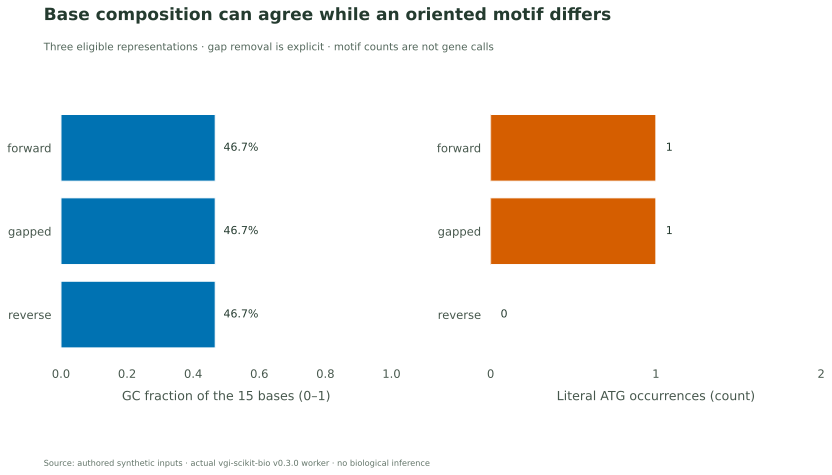

In [8]:
display(composition)
assert len(composition) == 3
prose(
    f"All **{len(composition)} eligible representations** contain {int(composition.residue_total.iloc[0])} bases and {int(composition.gc_bases.iloc[0])} G/C bases ({composition.gc_fraction.iloc[0]:.1%}). The reverse string changes which literal ATG motifs appear while preserving overall GC. Transcription returns to each original gapless DNA string; the reverse-complement predicate identifies the reverse row."
)
fig, axes = plt.subplots(1, 2, figsize=(12, 7))
axes[0].barh(composition.read_id, composition.gc_fraction, color="#0072B2")
axes[0].set_xlim(0, 1)
axes[0].set_xlabel("GC fraction of the 15 bases (0–1)")
for i, x in enumerate(composition.gc_fraction):
    axes[0].text(x + 0.025, i, f"{x:.1%}", va="center")
axes[1].barh(composition.read_id, composition.atg_occurrences, color="#D55E00")
axes[1].set_xlim(0, 2)
axes[1].set_xticks([0, 1, 2])
axes[1].set_xlabel("Literal ATG occurrences (count)")
for i, x in enumerate(composition.atg_occurrences):
    axes[1].text(x + 0.06, i, str(int(x)), va="center")
for ax in axes:
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
finish(
    fig,
    "Base composition can agree while an oriented motif differs",
    "Three eligible representations · gap removal is explicit · motif counts are not gene calls",
    SOURCE,
    name="base-versus-motif",
)

### A word-profile distance should state its orientation convention

`kmer_frequencies` counts overlapping windows. SQL verifies each count total equals `length − k + 1`. In the second representation, SQL groups each k-mer with its worker-computed reverse complement using the lexicographically smaller string as its key. This collapses orientation; it is not an alignment.

For each pair, shared probability mass is `sum(min(p, q))`, from 0 for disjoint profiles to 1 for identical profiles. Missing k-mers count as zero after the complete profile has been materialized. Both panels use the same scale.

In [9]:
%%sql
CREATE TABLE kmers AS SELECT * FROM skbio.sequence.kmer_frequencies(
 (SELECT read_id,seq FROM eligible ORDER BY read_id),id := 'read_id',k := {{KMER_K}});
CREATE TABLE profiles AS
SELECT 'oriented' AS representation,read_id,kmer AS token,sum(count) AS count FROM kmers GROUP BY ALL
UNION ALL
SELECT 'strand-collapsed',read_id,least(kmer,skbio.sequence.reverse_complement(kmer)),sum(count)
FROM kmers GROUP BY ALL;
CREATE TABLE weights AS SELECT *,count/sum(count) OVER(PARTITION BY representation,read_id) AS weight FROM profiles;
CREATE TABLE word_overlaps AS
SELECT a.representation,a.read_id AS id_1,b.read_id AS id_2,
 sum(least(x.weight,coalesce(y.weight,0))) AS shared_mass
FROM (SELECT DISTINCT representation,read_id FROM weights) a
JOIN (SELECT DISTINCT representation,read_id FROM weights) b USING(representation)
JOIN weights x ON x.representation=a.representation AND x.read_id=a.read_id
LEFT JOIN weights y ON y.representation=b.representation AND y.read_id=b.read_id AND y.token=x.token
GROUP BY a.representation,a.read_id,b.read_id;
SELECT read_id,sum(count) AS overlapping_windows,count(*) AS distinct_oriented_words
FROM kmers GROUP BY read_id ORDER BY read_id;

,read_id,overlapping_windows,distinct_oriented_words
0,forward,13.0,13
1,gapped,13.0,13
2,reverse,13.0,13


In [10]:
%%sql overlap <<
SELECT * FROM word_overlaps ORDER BY representation,id_1,id_2;

In [11]:
%%sql checks <<
SELECT 'all_six_inputs_audited' AS check_name,count(*)=6 AS passed FROM quality
UNION ALL SELECT 'three_unambiguous_profiles',count(*)=3 FROM eligible
UNION ALL SELECT 'missing_stays_unknown',valid_dna IS NULL AND gapless IS NULL FROM quality WHERE read_id='missing'
UNION ALL SELECT 'invalid_rejected',NOT valid_dna FROM quality WHERE read_id='malformed'
UNION ALL SELECT 'ambiguity_not_resolved',valid_dna AND has_degenerates FROM quality WHERE read_id='ambiguous'
UNION ALL SELECT 'rna_roundtrip',bool_and(back_to_dna=seq) FROM representations
UNION ALL SELECT 'strand_pair_verified',reverse_of_forward FROM representations WHERE read_id='reverse'
UNION ALL SELECT 'gc_two_reconstructions',bool_and(abs(gc_fraction-gc_bases/length(seq))<1e-12 AND gc_bases=(SELECT sum(count) FROM residues b WHERE b.read_id=r.read_id AND residue IN ('G','C'))) FROM representations r
UNION ALL SELECT 'all_windows_accounted',bool_and(n=length(seq)-{{KMER_K}}+1) FROM (SELECT read_id,sum(count) AS n FROM kmers GROUP BY read_id) JOIN eligible USING(read_id)
UNION ALL SELECT 'profile_mass_one',bool_and(abs(total-1)<1e-12) FROM (SELECT sum(weight) AS total FROM weights GROUP BY representation,read_id)
UNION ALL SELECT 'collapsed_profiles_identical',count(*)=9 AND bool_and(abs(shared_mass-1)<1e-12) FROM word_overlaps WHERE representation='strand-collapsed';

,check_name,passed
0,all_six_inputs_audited,True
1,three_unambiguous_profiles,True
2,missing_stays_unknown,True
3,invalid_rejected,True
4,ambiguity_not_resolved,True
5,rna_roundtrip,True
6,strand_pair_verified,True
7,gc_two_reconstructions,True
8,all_windows_accounted,True
9,profile_mass_one,True


At **k=3**, forward/reverse oriented profiles share **0.000** of their mass. After strand collapse all three profiles are identical (shared mass 1). The gapped input now matches the forward string because we deliberately removed its gap symbols. All **11 checks** pass.

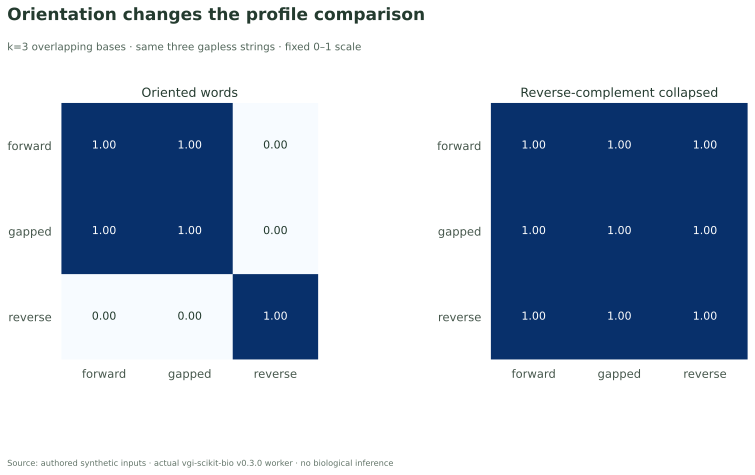

3990

In [12]:
display(checks)
assert checks.passed.all()
focus = overlap[
    (overlap.representation == "oriented")
    & (overlap.id_1 == "forward")
    & (overlap.id_2 == "reverse")
].iloc[0]
prose(
    f"At **k={KMER_K}**, forward/reverse oriented profiles share **{focus.shared_mass:.3f}** of their mass. After strand collapse all three profiles are identical (shared mass 1). The gapped input now matches the forward string because we deliberately removed its gap symbols. All **{len(checks)} checks** pass."
)
order = ["forward", "gapped", "reverse"]
fig, axes = plt.subplots(1, 2, figsize=(12, 7))
for ax, mode, title in zip(
    axes,
    ["oriented", "strand-collapsed"],
    ["Oriented words", "Reverse-complement collapsed"],
    strict=True,
):
    matrix = (
        overlap[overlap.representation == mode]
        .pivot(index="id_1", columns="id_2", values="shared_mass")
        .reindex(index=order, columns=order)
    )
    im = ax.imshow(matrix, vmin=0, vmax=1, cmap="Blues")
    ax.set_xticks(range(3), order)
    ax.set_yticks(range(3), order)
    ax.set_title(title)
    ax.grid(False)
    for i in range(3):
        for j in range(3):
            ax.text(
                j,
                i,
                f"{matrix.iloc[i, j]:.2f}",
                ha="center",
                va="center",
                color="white" if matrix.iloc[i, j] > 0.6 else "#20382B",
            )

finish(
    fig,
    "Orientation changes the profile comparison",
    f"k={KMER_K} overlapping bases · same three gapless strings · fixed 0–1 scale",
    SOURCE,
    name=f"word-overlap-{KMER_K}",
)
Path("artifacts/analysis-02.json").write_text(
    json.dumps(
        {
            "k": KMER_K,
            "composition": composition.to_dict("records"),
            "overlap": overlap.to_dict("records"),
            "checks": checks.to_dict("records"),
        },
        indent=2,
    )
)

### Experiment: change word length, retain the sequences

Change `KMER_K` from **3 to 2**. The available windows increase from 13 to 14 per eligible string. Oriented overlap can change; collapsed overlap must remain 1, since the strings differ only by orientation or the removed gaps. The quality audit, GC/motif chart and transcript round trips must stay fixed.

Neither high overlap nor alphabet validity identifies an organism. Canonicalizing words discards orientation, and gap removal changes coordinates. Choose those conventions deliberately before using a profile downstream.

In [13]:
session.close()
plt.close("all")

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-scikit-bio](https://github.com/Query-farm/vgi-scikit-bio)
